<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta9%C3%B6dev2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 23.8M/23.8M [00:01<00:00, 20.8MB/s]

Extracting files...


Veri seti klasoru: /root/.cache/kagglehub/datasets/tabishalam0/traffic-signs-dataset-germany-uk-usa/versions/1
Toplam gorsel sayisi: 2614
Kirmizi cember tespit edilen gorsel sayisi: 1122


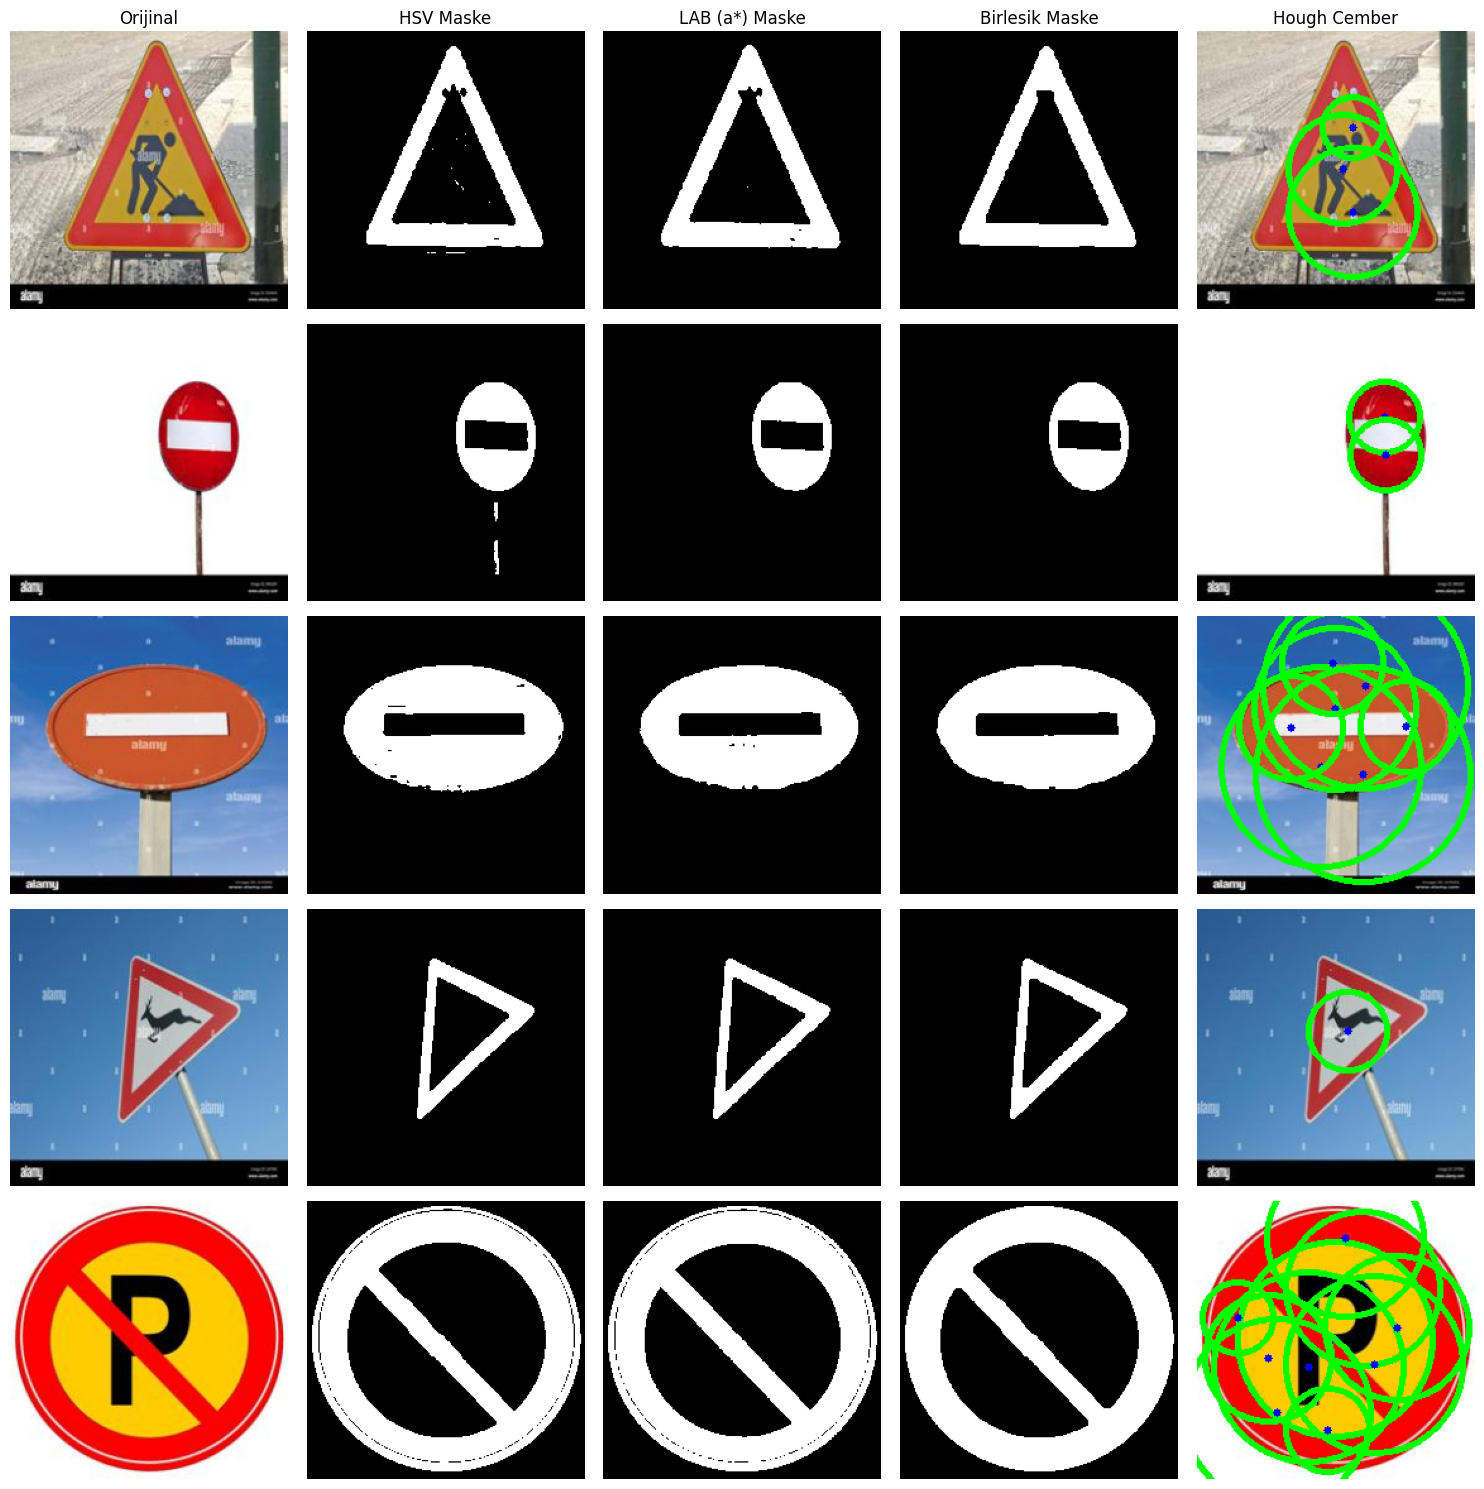

In [2]:
from pathlib import Path
import random
import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np

# 1. Veri setini indir
dataset_path = kagglehub.dataset_download(
    "tabishalam0/traffic-signs-dataset-germany-uk-usa"
)
print("Veri seti klasoru:", dataset_path)


def detect_red_circle_sign(image_path: Path):
    img = cv2.imread(str(image_path))
    if img is None:
        return None

    resized = cv2.resize(img, (220, 220))

    # --- Renk Uzayi 1: HSV ---
    hsv = cv2.cvtColor(resized, cv2.COLOR_BGR2HSV)
    mask_hsv_1 = cv2.inRange(hsv, np.array([0, 70, 50]), np.array([10, 255, 255]))
    mask_hsv_2 = cv2.inRange(
        hsv, np.array([170, 70, 50]), np.array([180, 255, 255])
    )
    hsv_red = cv2.bitwise_or(mask_hsv_1, mask_hsv_2)

    # --- Renk Uzayi 2: LAB (a* kanali kirmizi-yesil ekseni) ---
    lab = cv2.cvtColor(resized, cv2.COLOR_BGR2LAB)
    _, a_channel, _ = cv2.split(lab)
    _, lab_red = cv2.threshold(a_channel, 148, 255, cv2.THRESH_BINARY)

    # Iki renk uzayinin ortak kirmizi bolgesi ve morfolojik temizlik
    combined_red = cv2.bitwise_and(hsv_red, lab_red)
    kernel = np.ones((5, 5), np.uint8)
    combined_red = cv2.morphologyEx(combined_red, cv2.MORPH_CLOSE, kernel)
    combined_red = cv2.morphologyEx(
        combined_red, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)
    )

    blurred = cv2.GaussianBlur(combined_red, (9, 9), 2)

    # --- Hough Cember Donusumu ---
    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=30,
        param1=100,
        param2=18,
        minRadius=20,
        maxRadius=105,
    )

    output = resized.copy()
    detected = False

    if circles is not None:
        circles = np.uint16(np.around(circles[0, :]))
        for cx, cy, r in circles:
            ring_mask = np.zeros_like(combined_red)
            cv2.circle(ring_mask, (cx, cy), r, 255, thickness=5)
            ring_total = cv2.countNonZero(ring_mask)
            red_hits = cv2.countNonZero(
                cv2.bitwise_and(combined_red, ring_mask)
            )

            if ring_total > 0 and (red_hits / ring_total) > 0.30:
                detected = True
                cv2.circle(output, (cx, cy), r, (0, 255, 0), 3)
                cv2.circle(output, (cx, cy), 3, (255, 0, 0), -1)

    return resized, hsv_red, lab_red, combined_red, output, detected


# Veri setindeki gorselleri tara
valid_exts = {".jpg", ".jpeg", ".png", ".ppm", ".bmp"}
all_images = [
    p for p in Path(dataset_path).rglob("*") if p.suffix.lower() in valid_exts
]
print("Toplam gorsel sayisi:", len(all_images))

# Tespit edilen ornekleri topla
detected_results = []
for img_path in all_images:
    res = detect_red_circle_sign(img_path)
    if res is not None and res[5]:
        detected_results.append((img_path, res))

print("Kirmizi cember tespit edilen gorsel sayisi:", len(detected_results))

# Ornek sonuclari gorsellestir
num_show = min(5, len(detected_results))
if num_show > 0:
    samples = random.sample(detected_results, num_show)
    fig, axes = plt.subplots(num_show, 5, figsize=(15, 3 * num_show))
    titles = [
        "Orijinal",
        "HSV Maske",
        "LAB (a*) Maske",
        "Birlesik Maske",
        "Hough Cember",
    ]

    for i, (_, (orig, hsv_m, lab_m, comb_m, out, _)) in enumerate(samples):
        row_imgs = [
            cv2.cvtColor(orig, cv2.COLOR_BGR2RGB),
            hsv_m,
            lab_m,
            comb_m,
            cv2.cvtColor(out, cv2.COLOR_BGR2RGB),
        ]
        for j, im in enumerate(row_imgs):
            ax = axes[i, j] if num_show > 1 else axes[j]
            ax.imshow(im, cmap="gray" if j in [1, 2, 3] else None)
            if i == 0:
                ax.set_title(titles[j])
            ax.axis("off")

    plt.tight_layout()
    plt.show()